# Assignment 7 — Image Sharpening

> **Question:** Write a program to sharpen the input image using the three methods below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.moon()   # 'moon' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


In [3]:
f = img.astype(np.float64)

def to_uint8(x):
    return np.clip(np.round(x), 0, 255).astype(np.uint8)

def scale_for_display(x):
    """Linearly map any range to 0..255 (for showing edge / Laplacian images)."""
    x = x - x.min()
    return to_uint8(255 * x / x.max()) if x.max() > 0 else to_uint8(x)

def conv(image, kernel):
    return cv2.filter2D(image, cv2.CV_64F, np.asarray(kernel, dtype=np.float64), borderType=cv2.BORDER_REPLICATE)

## Part 1

> **Part 1:** Sharpen the input image using the Laplacian filter.

$$ \nabla^2 f = f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1) - 4f(x,y) $$

The kernel centre is negative, so the sharpened image is $g = f - \nabla^2 f$. The 4-neighbour kernel and the 8-neighbour kernel (which also includes diagonals) are both used.

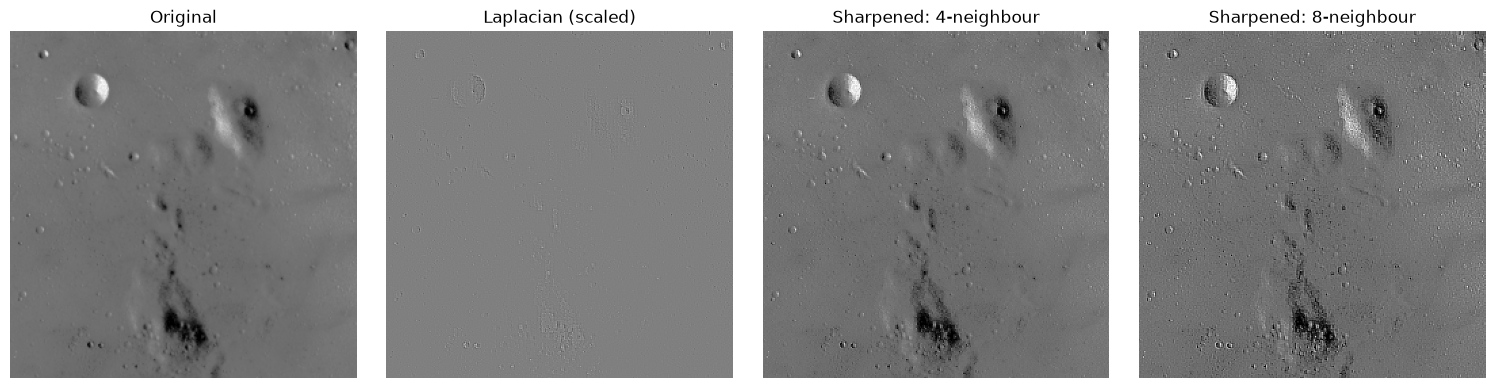

In [4]:
lap4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
lap8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]])

L4, L8 = conv(f, lap4), conv(f, lap8)
sharp_lap4 = to_uint8(f - L4)
sharp_lap8 = to_uint8(f - L8)

show([img, scale_for_display(L4), sharp_lap4, sharp_lap8],
     ['Original', 'Laplacian (scaled)', 'Sharpened: 4-neighbour', 'Sharpened: 8-neighbour'], cols=4, size=3.8)

## Part 2

> **Part 2:** Sharpen the input image using gradient operators of Sobel and the Canny edge detector.

### 2a. Sobel gradient

$$ G_x = \begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\quad
   G_y = \begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix},\quad
   M = \sqrt{g_x^2 + g_y^2} $$

The gradient magnitude is large at edges. Adding a scaled copy of it to the image strengthens the edges: $g = f + \alpha \cdot M_{norm}$.

Enter weight alpha for adding the Sobel gradient: no valid input, using default = 0.5


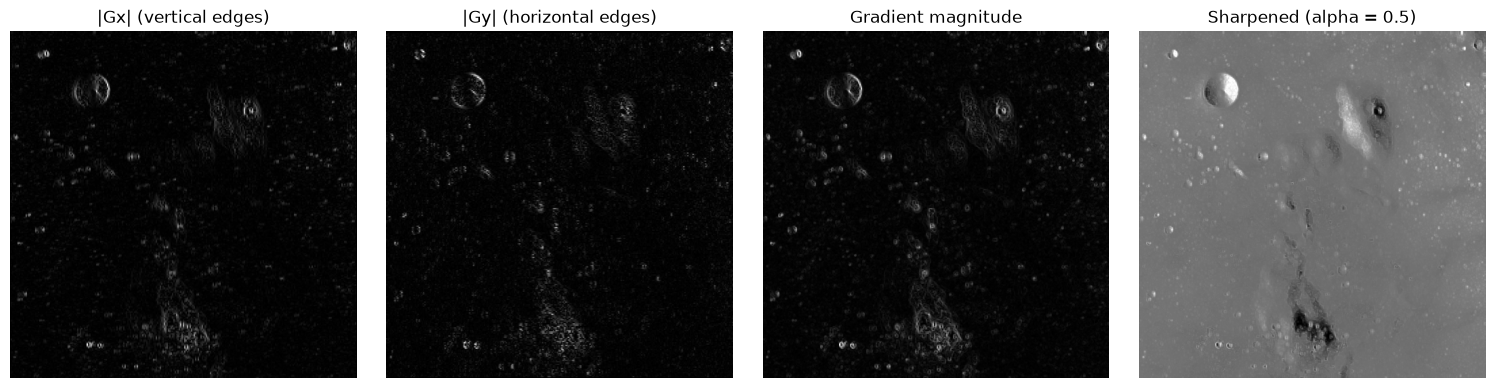

In [5]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.T

gx, gy = conv(f, sobel_x), conv(f, sobel_y)
mag = np.hypot(gx, gy)
mag_norm = 255 * mag / mag.max()

alpha = ask("Enter weight alpha for adding the Sobel gradient", 0.5)
sharp_sobel = to_uint8(f + alpha * mag_norm)

show([scale_for_display(np.abs(gx)), scale_for_display(np.abs(gy)), to_uint8(mag_norm), sharp_sobel],
     ['|Gx| (vertical edges)', '|Gy| (horizontal edges)', 'Gradient magnitude', f'Sharpened (alpha = {alpha})'],
     cols=4, size=3.8)

### 2b. Canny edge detector

Canny works in four steps: (1) Gaussian smoothing, (2) Sobel gradient magnitude and direction, (3) non-maximum suppression to thin the edges, (4) double threshold and hysteresis to keep strong edges plus the weak edges connected to them. The thin edge map it produces is added to the image to emphasise edges.

Enter Canny low threshold: no valid input, using default = 30
Enter Canny high threshold: no valid input, using default = 90
Enter weight beta for adding Canny edges: no valid input, using default = 0.25


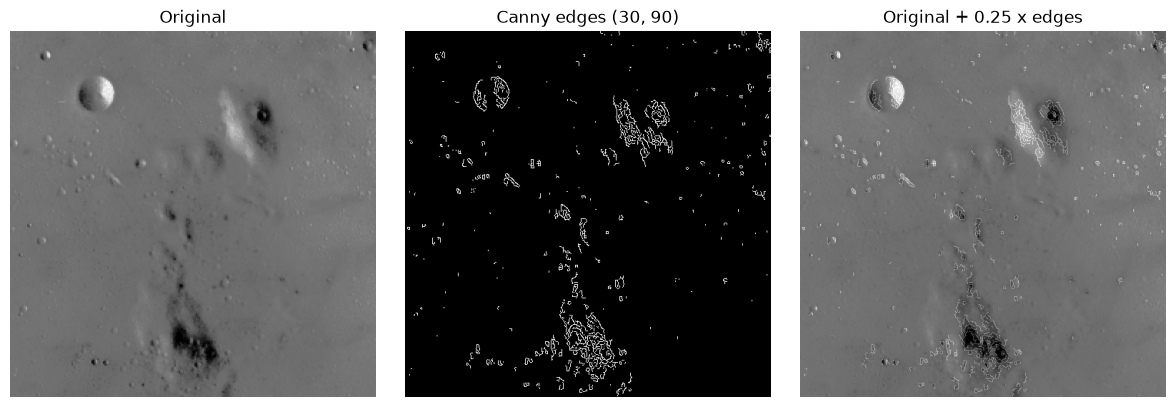

In [6]:
low = ask("Enter Canny low threshold", 30, int)
high = ask("Enter Canny high threshold", 90, int)
edges = cv2.Canny(img, low, high)                 # 0 / 255 edge map

beta = ask("Enter weight beta for adding Canny edges", 0.25)
sharp_canny = to_uint8(f + beta * edges)

show([img, edges, sharp_canny], ['Original', f'Canny edges ({low}, {high})', f'Original + {beta} x edges'])

## Part 3

> **Part 3:** Sharpen the input image using unsharp masking. To obtain the blurred image, use the Gaussian filter of size 5x5 and sigma = 3.

1. Blur: $\bar f = f * G_{5\times5,\,\sigma=3}$
2. Mask: $g_{mask} = f - \bar f$
3. Add back: $g = f + k\, g_{mask}$  — $k = 1$ is unsharp masking and $k > 1$ is high-boost filtering.

Enter k (1 = unsharp masking, >1 = high-boost): no valid input, using default = 1.0


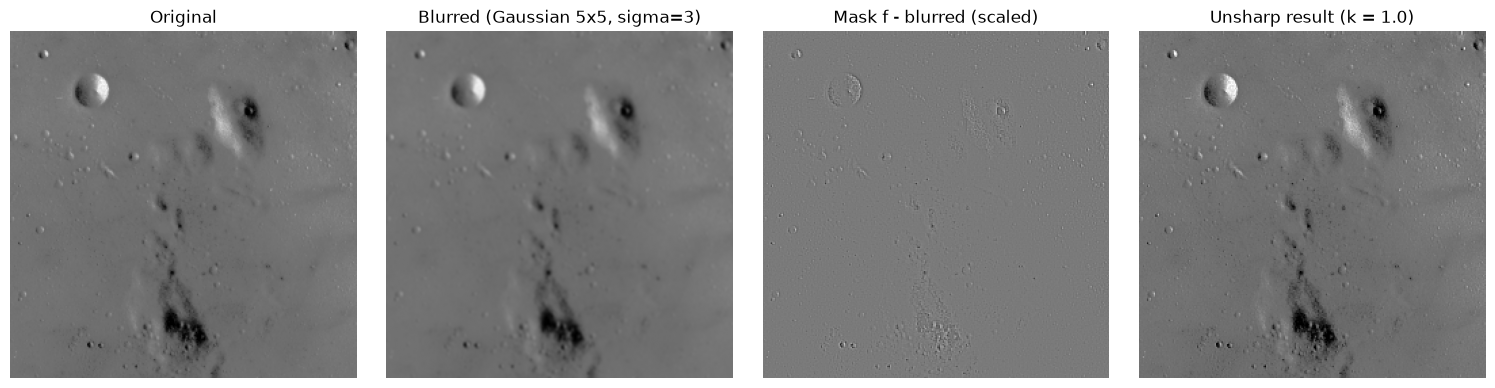

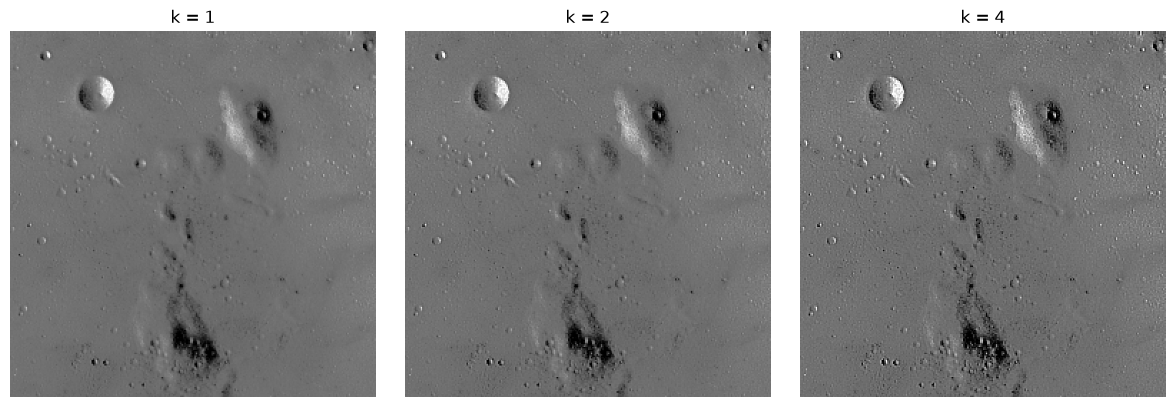

In [7]:
def gaussian_kernel(n, sigma):
    a = n // 2
    y, x = np.mgrid[-a:a + 1, -a:a + 1]
    h = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    return h / h.sum()

blurred = conv(f, gaussian_kernel(5, 3))
mask = f - blurred
k = ask("Enter k (1 = unsharp masking, >1 = high-boost)", 1.0)
sharp_unsharp = to_uint8(f + k * mask)

show([img, to_uint8(blurred), scale_for_display(mask), sharp_unsharp],
     ['Original', 'Blurred (Gaussian 5x5, sigma=3)', 'Mask f - blurred (scaled)', f'Unsharp result (k = {k})'],
     cols=4, size=3.8)
show([to_uint8(f + kk * mask) for kk in (1, 2, 4)], [f'k = {kk}' for kk in (1, 2, 4)])

## Comparison of all methods

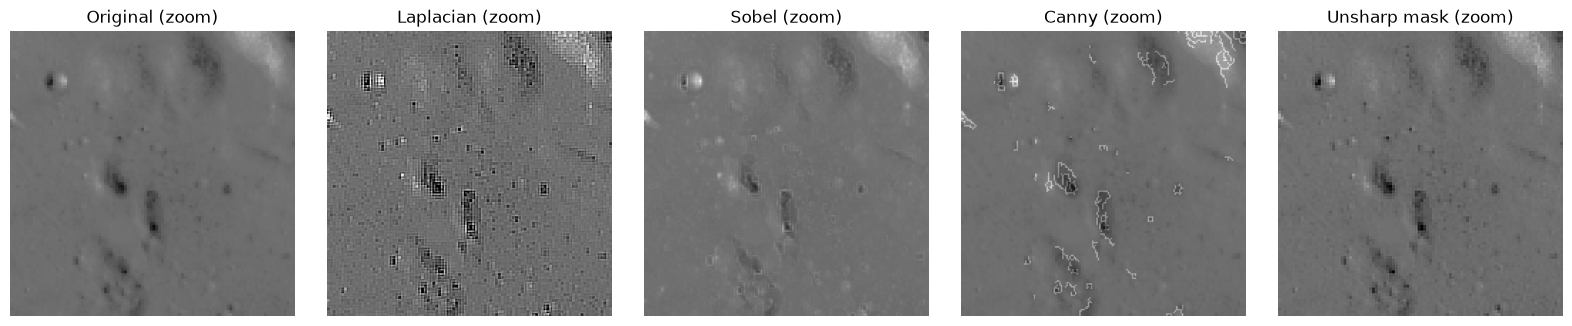

In [8]:
crop = (slice(150, 350), slice(150, 350))
results = [img, sharp_lap8, sharp_sobel, sharp_canny, sharp_unsharp]
names = ['Original', 'Laplacian', 'Sobel', 'Canny', 'Unsharp mask']
show([r[crop] for r in results], [n + ' (zoom)' for n in names], cols=5, size=3.2)

**Observations:**
- The **Laplacian** is a second-derivative filter. It brings out fine detail and is the strongest sharpener here, but it also amplifies noise. The 8-neighbour kernel gives a stronger effect than the 4-neighbour one.
- The **Sobel** gradient (first derivative) responds to edges in particular directions. Adding the magnitude highlights edges without amplifying flat regions as much as the Laplacian does.
- **Canny** produces thin, clean, one-pixel-wide edges. Adding them outlines the main structures rather than sharpening the texture.
- **Unsharp masking** adds back the high-frequency detail that blurring removed, which gives a natural-looking sharpening. A larger k (high-boost) makes the effect stronger.